# 01 — Exploration du dataset GTSDB (et aperçu de GTSRB)

**Projet :** Détection et reconnaissance des panneaux de signalisation pour l'ADAS
**Objectif du notebook :** comprendre les données *avant* d'entraîner quoi que ce soit.

Questions auxquelles ce notebook répond, avec des chiffres réels :

1. Les annotations sont-elles cohérentes ? (pourquoi `gt.txt` a 1213 lignes et non 1206 ?)
2. Combien d'images contiennent des panneaux, et combien par image ?
3. Comment les 43 classes et les 4 super-catégories sont-elles réparties ?
4. Quelle est la taille des panneaux ? (le point critique pour YOLO)
5. Où apparaissent-ils dans l'image ?
6. Le découpage officiel train / test est-il équilibré ?
7. Que contient GTSRB, et pourquoi est-il utile pour la reconnaissance ?

Toutes les figures sont enregistrées dans `results/exploration/` pour la présentation.

> Prérequis : `data/raw/FullIJCNN2013/` et `data/raw/GTSRB/` extraits (voir `data/README.md`),
> et le package du projet installé (`pip install -e .`).

In [1]:
import json
import os
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from roadsigns.datasets.gtsdb import CLASS_NAMES, SUPER_CATEGORIES, GTSDBDataset, super_category_id
from roadsigns.evaluation.matching import iou

# Repository root, whether the notebook runs from notebooks/ or from the root.
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

DATA_RAW = Path(os.environ.get("ROADSIGNS_DATA_RAW", REPO_ROOT / "data" / "raw"))
GTSDB_ROOT = DATA_RAW / "FullIJCNN2013"
GTSRB_ROOT = DATA_RAW / "GTSRB" / "Final_Training" / "Images"
OUT = REPO_ROOT / "results" / "exploration"
OUT.mkdir(parents=True, exist_ok=True)

IMG_W, IMG_H = 1360, 800          # documented GTSDB image size
OFFICIAL_TEST_START = 600         # IJCNN 2013 split: 00000-00599 train, 00600-00899 test
YOLO_IMGSZ = (640, 1024, 1280)    # input sizes we are considering for YOLO

sns.set_theme(style="whitegrid", context="notebook")
SUPER_COLORS = {"prohibitory": "#d1495b", "danger": "#edae49", "mandatory": "#00798c", "other": "#6c757d"}

summary: dict = {}


def save(fig, name: str) -> None:
    path = OUT / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved -> {path.relative_to(REPO_ROOT) if path.is_relative_to(REPO_ROOT) else path}")


print("GTSDB:", GTSDB_ROOT, "| exists:", GTSDB_ROOT.is_dir())
print("GTSRB:", GTSRB_ROOT, "| exists:", GTSRB_ROOT.is_dir())

GTSDB: C:\Users\pc\Desktop\projetcomputer vision\road-sign-recognition-adas\data\raw\FullIJCNN2013 | exists: True
GTSRB: C:\Users\pc\Desktop\projetcomputer vision\road-sign-recognition-adas\data\raw\GTSRB\Final_Training\Images | exists: True


## 1. Intégrité du fichier d'annotations `gt.txt`

La description officielle annonce **1206 panneaux**, mais `gt.txt` compte **1213 lignes**.
On vérifie : lignes vides, doublons exacts, et annotations quasi identiques (même image, boîtes
qui se recouvrent presque entièrement).

In [2]:
raw_lines = (GTSDB_ROOT / "gt.txt").read_text(encoding="utf-8").splitlines()
non_empty = [line.strip() for line in raw_lines if line.strip()]
exact_dups = {line: n for line, n in Counter(non_empty).items() if n > 1}

print(f"Lignes dans gt.txt            : {len(raw_lines)}")
print(f"Lignes non vides (annotations) : {len(non_empty)}")
print(f"Lignes vides                   : {len(raw_lines) - len(non_empty)}")
print(f"Doublons exacts                : {sum(n - 1 for n in exact_dups.values())}")
for line, n in exact_dups.items():
    print(f"   {line}  (x{n})")

summary["gt_txt_lines"] = len(raw_lines)
summary["annotations"] = len(non_empty)
summary["exact_duplicate_lines"] = sum(n - 1 for n in exact_dups.values())

Lignes dans gt.txt            : 1213
Lignes non vides (annotations) : 1213
Lignes vides                   : 0
Doublons exacts                : 1
   00340.ppm;827;543;851;567;14  (x2)


In [3]:
ds = GTSDBDataset.load(GTSDB_ROOT)

rows = []
for filename, signs in ds.annotations.items():
    for s in signs:
        rows.append({
            "filename": filename,
            "image_id": int(Path(filename).stem),
            "class_id": s.class_id,
            "class_name": s.class_name,
            "super_category": s.super_category,
            "x1": s.x1, "y1": s.y1, "x2": s.x2, "y2": s.y2,
            "w": s.width, "h": s.height,
        })
df = pd.DataFrame(rows)
df["size"] = df[["w", "h"]].max(axis=1)              # longest side, in pixels
df["cx"] = (df["x1"] + df["x2"]) / 2
df["cy"] = (df["y1"] + df["y2"]) / 2
df["split"] = np.where(df["image_id"] >= OFFICIAL_TEST_START, "test", "train")

# Near-duplicates: two annotations in the same image whose boxes overlap almost completely.
near_dups = []
for filename, group in df.groupby("filename"):
    boxes = group[["x1", "y1", "x2", "y2"]].to_numpy(dtype=float)
    ids = group["class_id"].to_numpy()
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            v = iou(tuple(boxes[i]), tuple(boxes[j]))
            if v > 0.7:
                near_dups.append((filename, int(ids[i]), int(ids[j]), round(v, 2)))

print(f"Annotations chargées : {len(df)}")
print(f"Paires d'annotations quasi identiques (IoU > 0.7) : {len(near_dups)}")
for item in near_dups[:15]:
    print("   image {} : classes {} et {}, IoU {}".format(*item))
summary["near_duplicate_pairs"] = len(near_dups)

Annotations chargées : 1213
Paires d'annotations quasi identiques (IoU > 0.7) : 1
   image 00340.ppm : classes 14 et 14, IoU 1.0


**À interpréter :** si l'écart 1213 / 1206 s'explique par des doublons, on les retirera lors de la
conversion au format YOLO (sinon le modèle verrait deux fois le même panneau). S'il n'y a ni doublon
ni ligne vide, l'écart vient d'une mise à jour des annotations après publication : on le documente
et on garde les 1213 annotations.

## 2. Images : lisibilité, taille, et boîtes hors limites

In [4]:
sizes, unreadable = Counter(), []
for path in ds.image_paths:
    img = cv2.imread(str(path))
    if img is None:
        unreadable.append(path.name)
    else:
        sizes[(img.shape[1], img.shape[0])] += 1

out_of_bounds = df[(df.x1 < 0) | (df.y1 < 0) | (df.x2 >= IMG_W) | (df.y2 >= IMG_H)]
print(f"Images                   : {len(ds.image_paths)}")
print(f"Images illisibles        : {len(unreadable)} {unreadable[:5]}")
print(f"Tailles (largeur, hauteur): {dict(sizes)}")
print(f"Boîtes hors de l'image   : {len(out_of_bounds)}")

summary["images"] = len(ds.image_paths)
summary["unreadable_images"] = len(unreadable)
summary["image_sizes"] = {f"{w}x{h}": n for (w, h), n in sizes.items()}
summary["boxes_out_of_bounds"] = len(out_of_bounds)

Images                   : 900
Images illisibles        : 0 []
Tailles (largeur, hauteur): {(1360, 800): 900}
Boîtes hors de l'image   : 0


## 3. Panneaux par image

Images avec au moins un panneau : 741
Images sans panneau (fond seul) : 159 (18%)
Maximum de panneaux par image   : 6
saved -> results\exploration\01_signs_per_image.png


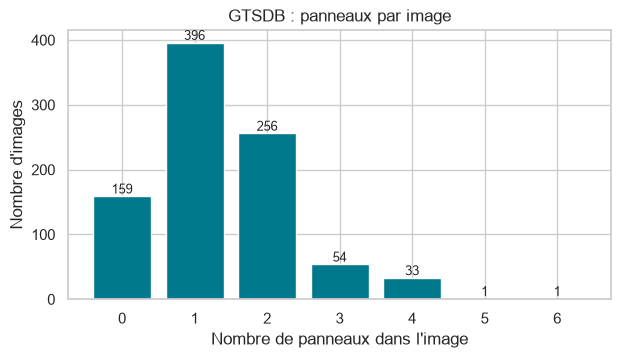

In [5]:
per_image = pd.Series({p.name: len(ds.signs_in(p)) for p in ds.image_paths})
n_empty = int((per_image == 0).sum())
print(f"Images avec au moins un panneau : {len(per_image) - n_empty}")
print(f"Images sans panneau (fond seul) : {n_empty} ({n_empty / len(per_image):.0%})")
print(f"Maximum de panneaux par image   : {per_image.max()}")

fig, ax = plt.subplots(figsize=(7, 3.5))
counts = per_image.value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color="#00798c")
for x, y in zip(counts.index.astype(str), counts.values):
    ax.text(x, y, str(y), ha="center", va="bottom", fontsize=9)
ax.set(xlabel="Nombre de panneaux dans l'image", ylabel="Nombre d'images",
       title="GTSDB : panneaux par image")
save(fig, "01_signs_per_image")
plt.show()

summary["images_with_signs"] = int(len(per_image) - n_empty)
summary["images_without_signs"] = n_empty
summary["max_signs_per_image"] = int(per_image.max())

Les images sans panneau sont utiles : elles apprennent au détecteur à **ne rien détecter** sur un
fond routier (réduction des fausses alarmes). On les garde à l'entraînement.

## 4. Répartition des 43 classes et des 4 super-catégories

saved -> results\exploration\02_class_distribution.png


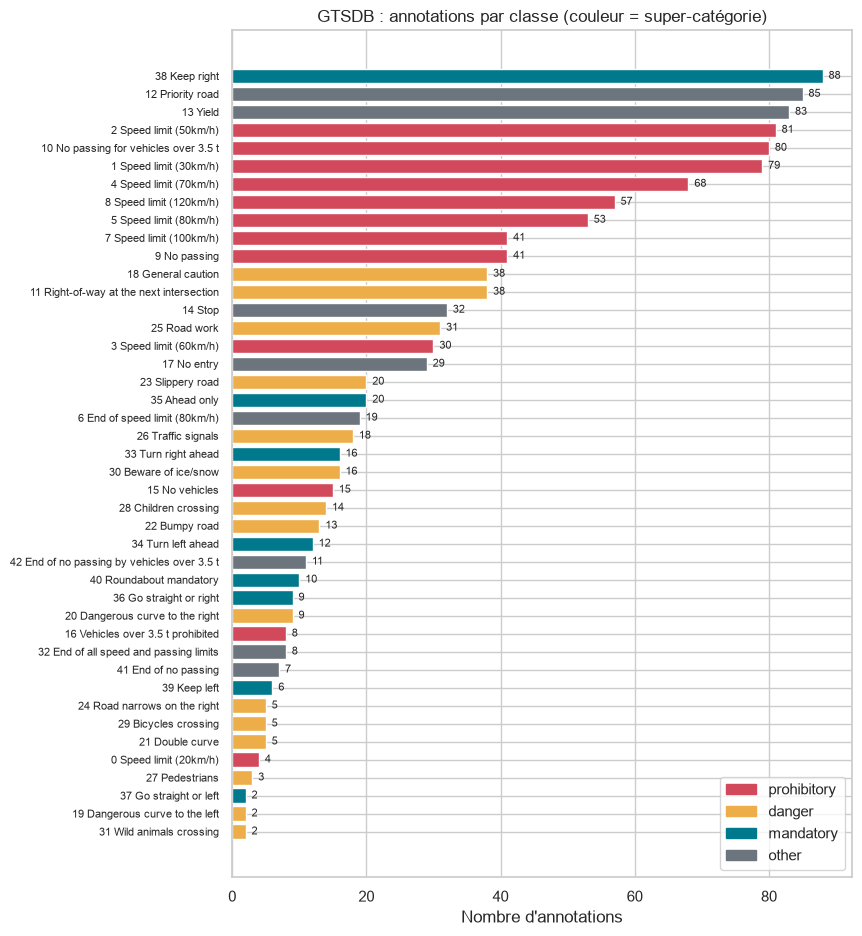

Classe la plus fréquente : Keep right (88)
Classes absentes du dataset          : []
Classes avec < 5 exemples dans le train : 9 sur 43


In [6]:
class_counts = df["class_id"].value_counts().reindex(range(43), fill_value=0)
order = class_counts.sort_values().index
colors = [SUPER_COLORS[SUPER_CATEGORIES[super_category_id(c)]] for c in order]

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh([f"{c:>2} {CLASS_NAMES[c]}" for c in order], class_counts[order].values, color=colors)
for i, v in enumerate(class_counts[order].values):
    ax.text(v + class_counts.max() * 0.01, i, str(v), va="center", fontsize=8)
ax.set(xlabel="Nombre d'annotations", title="GTSDB : annotations par classe (couleur = super-catégorie)")
ax.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SUPER_COLORS.values()]
ax.legend(handles, SUPER_COLORS.keys(), loc="lower right")
save(fig, "02_class_distribution")
plt.show()

train_counts = df[df.split == "train"]["class_id"].value_counts().reindex(range(43), fill_value=0)
rare = [c for c in range(43) if train_counts[c] < 5]
print(f"Classe la plus fréquente : {CLASS_NAMES[class_counts.idxmax()]} ({class_counts.max()})")
print(f"Classes absentes du dataset          : {[c for c in range(43) if class_counts[c] == 0]}")
print(f"Classes avec < 5 exemples dans le train : {len(rare)} sur 43")
summary["classes_absent"] = [int(c) for c in range(43) if class_counts[c] == 0]
summary["classes_lt5_train"] = len(rare)
summary["most_frequent_class"] = CLASS_NAMES[int(class_counts.idxmax())]

split           train  test  total
super_category                    
prohibitory       396   161    557
danger            156    63    219
mandatory         114    49    163
other             186    88    274
saved -> results\exploration\03_super_categories_split.png


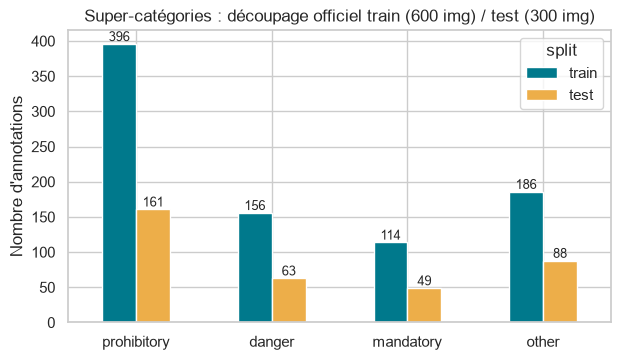

In [7]:
super_split = (df.groupby(["super_category", "split"]).size().unstack(fill_value=0)
               .reindex(SUPER_CATEGORIES).reindex(columns=["train", "test"], fill_value=0))
print(super_split.assign(total=super_split.sum(axis=1)))

fig, ax = plt.subplots(figsize=(7, 3.8))
super_split.plot.bar(ax=ax, color=["#00798c", "#edae49"], rot=0)
ax.set(xlabel="", ylabel="Nombre d'annotations",
       title="Super-catégories : découpage officiel train (600 img) / test (300 img)")
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
save(fig, "03_super_categories_split")
plt.show()

summary["super_categories"] = {k: int(v) for k, v in super_split.sum(axis=1).items()}

**Conséquence pour notre approche :** avec 43 classes et quelques centaines d'annotations
d'entraînement, beaucoup de classes ont trop peu d'exemples pour qu'un détecteur YOLO les apprenne.
En regroupant en **4 super-catégories**, chaque classe du détecteur a assez d'exemples. La classe
exacte sera donnée par le **CNN entraîné sur GTSRB** (section 8). C'est la justification chiffrée de
l'architecture en deux étapes.

## 5. Taille des panneaux — le point critique pour YOLO

count    1213.0
mean       45.2
std        22.1
min        17.0
10%        24.0
25%        29.0
50%        39.0
75%        55.0
90%        75.0
max       129.0
Panneaux de moins de 16 px :  0.0%
Panneaux de moins de 24 px :  9.2%
Panneaux de moins de 32 px : 30.8%
Panneaux de moins de 48 px : 66.8%

Taille médiane après redimensionnement de l'image pour YOLO :
  imgsz=640   -> facteur 0.47 -> médiane  18.4 px, 35.9% des panneaux sous 16 px
  imgsz=1024  -> facteur 0.75 -> médiane  29.4 px,  4.0% des panneaux sous 16 px
  imgsz=1280  -> facteur 0.94 -> médiane  36.7 px,  0.0% des panneaux sous 16 px
saved -> results\exploration\04_sign_sizes.png


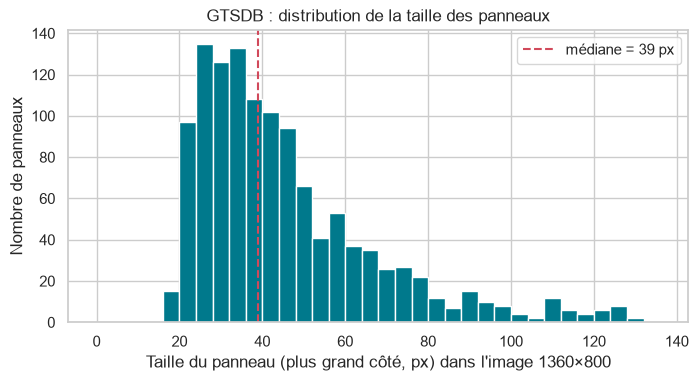

In [8]:
s = df["size"]
print(s.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_string())
for t in (16, 24, 32, 48):
    print(f"Panneaux de moins de {t:>2} px : {(s < t).mean():5.1%}")

print("\nTaille médiane après redimensionnement de l'image pour YOLO :")
for imgsz in YOLO_IMGSZ:
    scale = imgsz / IMG_W
    print(f"  imgsz={imgsz:<5} -> facteur {scale:.2f} -> médiane {s.median() * scale:5.1f} px, "
          f"{(s * scale < 16).mean():5.1%} des panneaux sous 16 px")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(s, bins=range(0, int(s.max()) + 8, 4), color="#00798c", edgecolor="white")
ax.axvline(s.median(), color="#d1495b", linestyle="--", label=f"médiane = {s.median():.0f} px")
ax.set(xlabel="Taille du panneau (plus grand côté, px) dans l'image 1360×800",
       ylabel="Nombre de panneaux", title="GTSDB : distribution de la taille des panneaux")
ax.legend()
save(fig, "04_sign_sizes")
plt.show()

summary["size_px"] = {"min": int(s.min()), "median": float(s.median()), "max": int(s.max()),
                      "pct_below_32": round(float((s < 32).mean()), 3)}
summary["median_size_at_imgsz"] = {imgsz: round(float(s.median() * imgsz / IMG_W), 1) for imgsz in YOLO_IMGSZ}

**À retenir pour la présentation :** YOLO redimensionne l'image d'entrée. À `imgsz=640`, l'image
est réduite d'un facteur ~0,47 et les petits panneaux deviennent minuscules. C'est la raison chiffrée
pour laquelle on entraînera à **1024 ou 1280**, au prix d'un entraînement plus lourd (GPU / Colab).

## 6. Où se trouvent les panneaux dans l'image ?

saved -> results\exploration\05_sign_positions.png


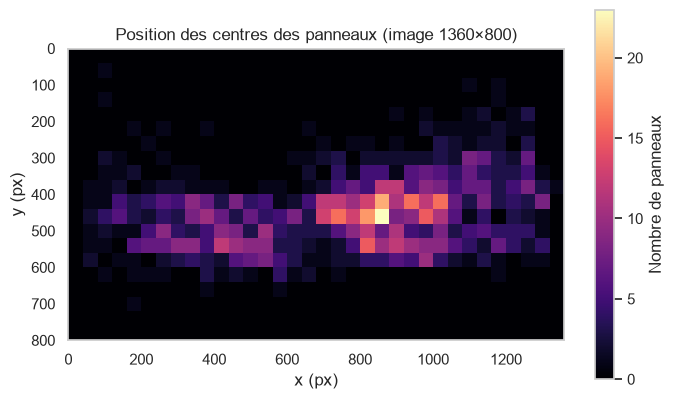

Panneaux dans la moitié droite : 66% | dans la moitié haute : 24%


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
h = ax.hist2d(df["cx"], df["cy"], bins=[34, 20], range=[[0, IMG_W], [0, IMG_H]], cmap="magma")
ax.invert_yaxis()
ax.set_aspect("equal")
fig.colorbar(h[3], ax=ax, label="Nombre de panneaux")
ax.set(xlabel="x (px)", ylabel="y (px)", title="Position des centres des panneaux (image 1360×800)")
save(fig, "05_sign_positions")
plt.show()

right = (df["cx"] > IMG_W / 2).mean()
upper = (df["cy"] < IMG_H / 2).mean()
print(f"Panneaux dans la moitié droite : {right:.0%} | dans la moitié haute : {upper:.0%}")
summary["pct_right_half"] = round(float(right), 3)
summary["pct_upper_half"] = round(float(upper), 3)

Les panneaux se concentrent dans une **bande horizontale autour de la ligne d'horizon** (y ≈ 400–550 px) : seulement 24 % sont dans la moitié haute de l'image. **66 % sont dans la moitié droite**, car en Allemagne on roule à droite.

C'est aussi un argument contre l'augmentation par **retournement horizontal** : elle déplacerait les panneaux à gauche et inverserait leur sens (« tourner à droite » deviendrait « tourner à gauche »).

## 7. Exemples annotés

saved -> results\exploration\06_annotated_examples.png


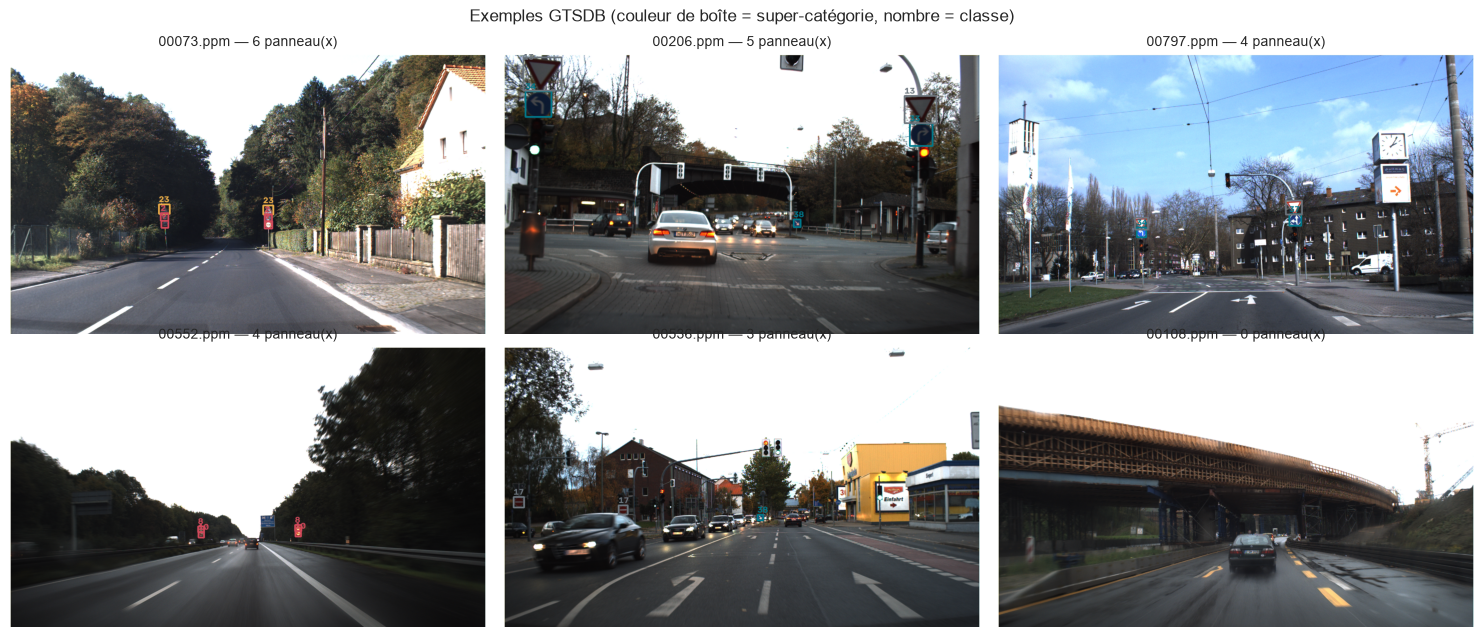

In [10]:
def draw_scene(path):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    for sgn in ds.signs_in(path):
        color = tuple(int(SUPER_COLORS[sgn.super_category].lstrip("#")[i:i + 2], 16) for i in (0, 2, 4))
        cv2.rectangle(img, (sgn.x1, sgn.y1), (sgn.x2, sgn.y2), color, 3)
        cv2.putText(img, str(sgn.class_id), (sgn.x1, max(15, sgn.y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)
    return img

busiest = per_image.sort_values(ascending=False).index[:3].tolist()
smallest = df.sort_values("size")["filename"].drop_duplicates().iloc[:2].tolist()
empty = per_image[per_image == 0].index[:1].tolist()
picks = list(dict.fromkeys(busiest + smallest + empty))[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, name in zip(axes.ravel(), picks):
    ax.imshow(draw_scene(GTSDB_ROOT / name))
    ax.set_title(f"{name} — {len(ds.signs_in(GTSDB_ROOT / name))} panneau(x)", fontsize=10)
    ax.axis("off")
for ax in axes.ravel()[len(picks):]:
    ax.axis("off")
fig.suptitle("Exemples GTSDB (couleur de boîte = super-catégorie, nombre = classe)", fontsize=12)
fig.tight_layout()
save(fig, "06_annotated_examples")
plt.show()

saved -> results\exploration\07_one_crop_per_class.png


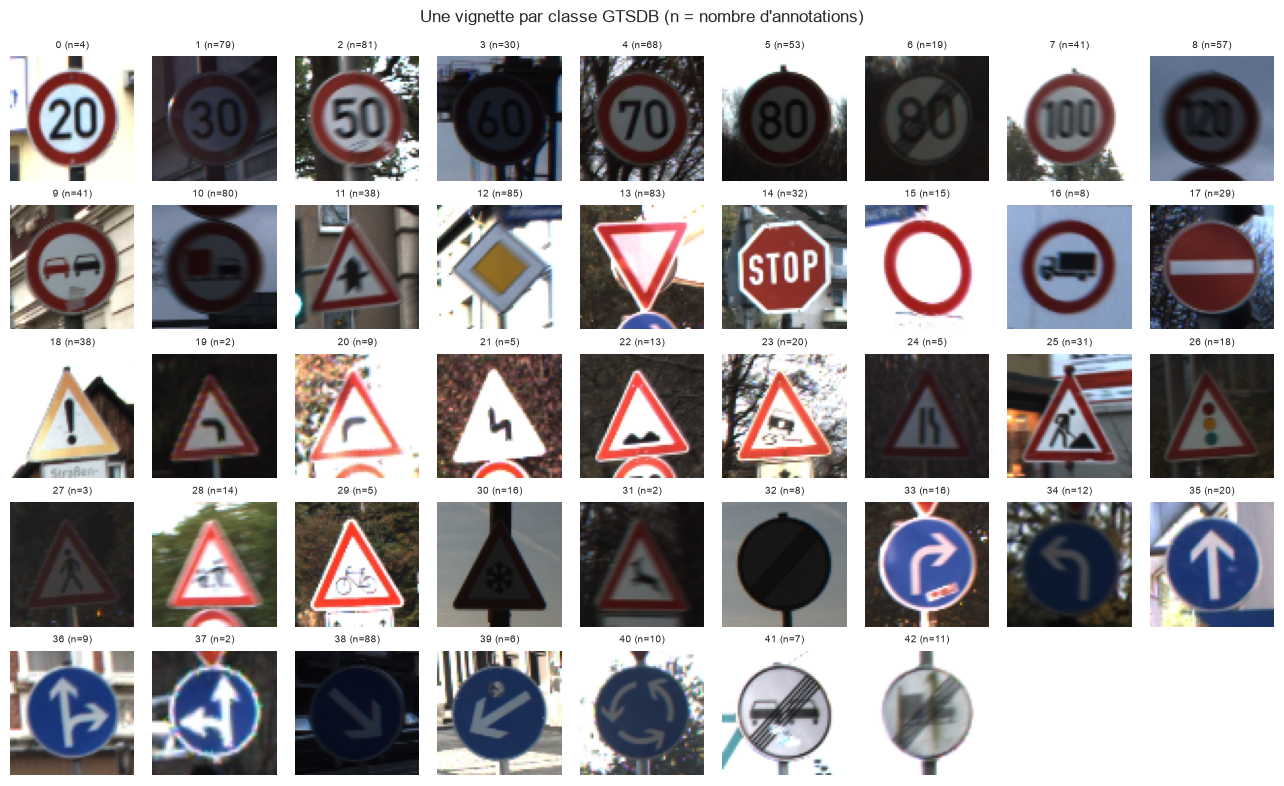

In [11]:
# One crop per class (taken from the scene images): what the 43 classes look like in GTSDB.
TILE = 64
fig, axes = plt.subplots(5, 9, figsize=(13, 8))
for c, ax in zip(range(45), axes.ravel()):
    ax.axis("off")
    if c >= 43:
        continue
    sub = df[df.class_id == c]
    if sub.empty:
        ax.set_title(f"{c}: absent", fontsize=7, color="#d1495b")
        continue
    r = sub.sort_values("size", ascending=False).iloc[0]
    img = cv2.imread(str(GTSDB_ROOT / r.filename))
    pad = int(0.15 * r["size"])
    crop = img[max(0, r.y1 - pad): r.y2 + pad + 1, max(0, r.x1 - pad): r.x2 + pad + 1]
    ax.imshow(cv2.cvtColor(cv2.resize(crop, (TILE, TILE)), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{c} (n={len(sub)})", fontsize=7)
fig.suptitle("Une vignette par classe GTSDB (n = nombre d'annotations)", fontsize=12)
fig.tight_layout()
save(fig, "07_one_crop_per_class")
plt.show()

## 8. Aperçu de GTSRB (reconnaissance)

GTSRB contient des panneaux **déjà découpés**, regroupés en *tracks* : 30 images successives du
**même panneau physique**. Pour la validation du CNN, il faudra garder chaque track entier du même côté
(sinon le modèle « reconnaît » des images quasi identiques à celles vues à l'entraînement).

Images GTSRB : 39209 | classes : 43 | tracks : 1307
Taille des images : min 25 px, médiane 44 px, max 243 px
saved -> results\exploration\08_gtsdb_vs_gtsrb.png


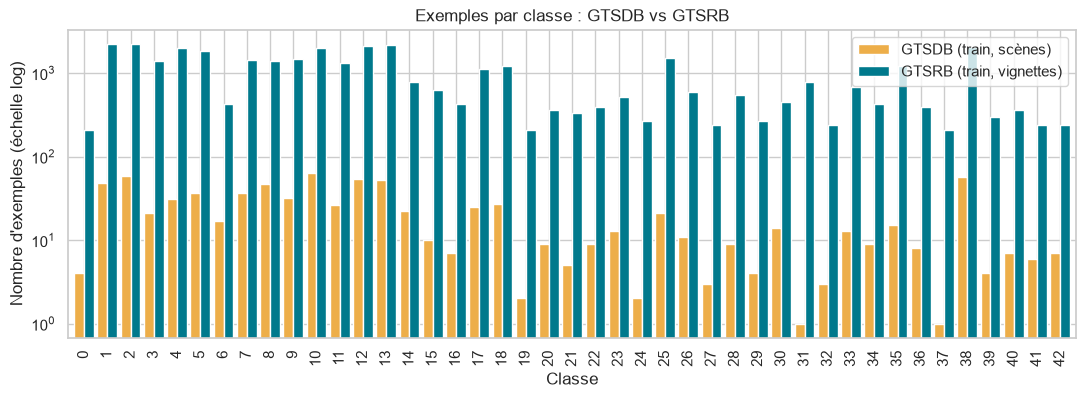

GTSRB fournit environ 46x plus d'exemples de panneaux que le train GTSDB.


In [12]:
if not GTSRB_ROOT.is_dir():
    print("GTSRB non trouvé : section ignorée.")
else:
    frames = []
    for csv_path in sorted(GTSRB_ROOT.glob("*/GT-*.csv")):
        part = pd.read_csv(csv_path, sep=";")
        part["track"] = part["Filename"].str.split("_").str[0]
        frames.append(part)
    gtsrb = pd.concat(frames, ignore_index=True)
    gtsrb["size"] = gtsrb[["Width", "Height"]].max(axis=1)
    tracks = gtsrb.groupby(["ClassId", "track"]).ngroups

    print(f"Images GTSRB : {len(gtsrb)} | classes : {gtsrb.ClassId.nunique()} | tracks : {tracks}")
    print(f"Taille des images : min {gtsrb['size'].min()} px, médiane {gtsrb['size'].median():.0f} px, "
          f"max {gtsrb['size'].max()} px")

    r_counts = gtsrb["ClassId"].value_counts().reindex(range(43), fill_value=0)
    d_counts = df[df.split == "train"]["class_id"].value_counts().reindex(range(43), fill_value=0)
    comp = pd.DataFrame({"GTSDB (train, scènes)": d_counts, "GTSRB (train, vignettes)": r_counts})

    fig, ax = plt.subplots(figsize=(13, 4))
    comp.plot.bar(ax=ax, logy=True, width=0.85, color=["#edae49", "#00798c"])
    ax.set(xlabel="Classe", ylabel="Nombre d'exemples (échelle log)",
           title="Exemples par classe : GTSDB vs GTSRB")
    save(fig, "08_gtsdb_vs_gtsrb")
    plt.show()

    ratio = r_counts.sum() / max(1, d_counts.sum())
    print(f"GTSRB fournit environ {ratio:.0f}x plus d'exemples de panneaux que le train GTSDB.")
    summary["gtsrb"] = {"images": int(len(gtsrb)), "tracks": int(tracks),
                        "median_size_px": float(gtsrb["size"].median()),
                        "ratio_vs_gtsdb_train": round(float(ratio), 1)}

## 9. Synthèse (chiffres pour la slide « Avancement »)

In [13]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nFigures :", sorted(p.name for p in OUT.glob("*.png")))

{
  "gt_txt_lines": 1213,
  "annotations": 1213,
  "exact_duplicate_lines": 1,
  "near_duplicate_pairs": 1,
  "images": 900,
  "unreadable_images": 0,
  "image_sizes": {
    "1360x800": 900
  },
  "boxes_out_of_bounds": 0,
  "images_with_signs": 741,
  "images_without_signs": 159,
  "max_signs_per_image": 6,
  "classes_absent": [],
  "classes_lt5_train": 9,
  "most_frequent_class": "Keep right",
  "super_categories": {
    "prohibitory": 557,
    "danger": 219,
    "mandatory": 163,
    "other": 274
  },
  "size_px": {
    "min": 17,
    "median": 39.0,
    "max": 129,
    "pct_below_32": 0.308
  },
  "median_size_at_imgsz": {
    "640": 18.4,
    "1024": 29.4,
    "1280": 36.7
  },
  "pct_right_half": 0.656,
  "pct_upper_half": 0.238,
  "gtsrb": {
    "images": 39209,
    "tracks": 1307,
    "median_size_px": 44.0,
    "ratio_vs_gtsdb_train": 46.0
  }
}

Figures : ['01_signs_per_image.png', '02_class_distribution.png', '03_super_categories_split.png', '04_sign_sizes.png', '05_sign_pos

### Conclusions de l'exploration

- **Qualité des annotations :** `gt.txt` contient 1213 lignes, dont **1 doublon exact** (image 00340, un panneau Stop annoté deux fois), soit **1212 annotations uniques**. Les 6 annotations de plus que les 1206 de la description officielle proviennent probablement d'une mise à jour : nous les gardons et retirons le doublon lors de la conversion YOLO.
- **Images :** 900 images en 1360×800, toutes lisibles ; 741 contiennent au moins un panneau, **159 n'en contiennent aucun (18 %)** : nous les gardons comme exemples négatifs.
- **Déséquilibre des classes :** les 43 classes sont présentes, mais **9 classes ont moins de 5 exemples d'entraînement** (minimum : 2). Le détecteur sera donc entraîné sur **4 super-catégories** (prohibitory 557, danger 219, mandatory 163, other 274 annotations).
- **Petits objets :** taille médiane **39 px**, 31 % des panneaux font moins de 32 px. À `imgsz=640`, **36 % des panneaux tomberaient sous 16 px** (4 % à 1024, 0 % à 1280) : nous entraînerons à **1024 minimum, 1280 si le GPU le permet**.
- **Position :** les panneaux sont concentrés autour de la ligne d'horizon et à 66 % à droite : pas de retournement horizontal.
- **GTSRB** fournit environ **46 fois plus d'exemples par classe** que GTSDB : la classe exacte (43 classes) sera donnée par un **CNN entraîné sur GTSRB**, en deuxième étape.